**Dataset Loading**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [3]:
import os
import glob

matches = glob.glob(
    "/content/drive/MyDrive/**/paysim.zip",
    recursive=True
)

if not matches:
    raise FileNotFoundError(
        "paysim.zip nahi mili. MyDrive mein file location check karo."
    )

zip_path = matches[0]

print("ZIP file found:", zip_path)
print("File size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

ZIP file found: /content/drive/MyDrive/MAJOR PROJECT MAIN/paysim.zip
File size (MB): 177.75


In [4]:
import zipfile
import os
import glob
import pandas as pd
import numpy as np

extract_dir = "/content/paysim_extracted"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    csv_files_in_zip = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX/")
    ]

    if not csv_files_in_zip:
        raise ValueError("ZIP file ke andar koi CSV file nahi mili.")

    print("CSV files inside ZIP:")
    for name in csv_files_in_zip:
        print(name)

    # Extract CSV files only
    for name in csv_files_in_zip:
        if os.path.basename(name) != name:
            raise ValueError(
                "ZIP mein nested folder hai. CSV ko safely extract "
                "karne ke liye archive structure inspect karo."
            )
        z.extract(name, extract_dir)

csv_paths = [
    os.path.join(extract_dir, name)
    for name in csv_files_in_zip
]

csv_path = max(csv_paths, key=os.path.getsize)

print("\nSelected CSV:", csv_path)

df = pd.read_csv(csv_path)

print("Dataset loaded!")
print("Shape:", df.shape)
display(df.head())

CSV files inside ZIP:
paysim dataset.csv

Selected CSV: /content/paysim_extracted/paysim dataset.csv
Dataset loaded!
Shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFraud distribution:")
print(df["isFraud"].value_counts(dropna=False))

print("\nFraud percentage:")
print((df["isFraud"].value_counts(normalize=True) * 100).round(4))

Columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate row

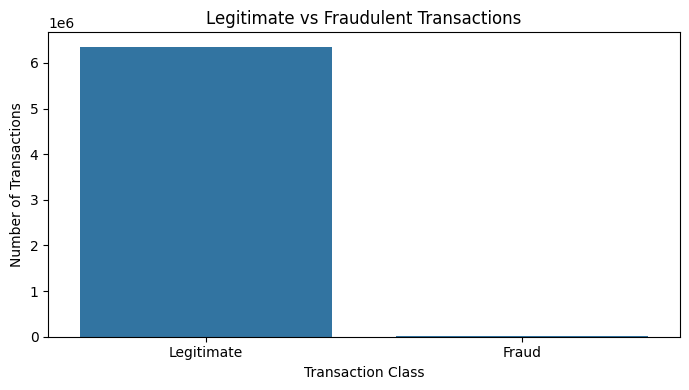

In [6]:
fraud_counts = df["isFraud"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
sns.barplot(x=fraud_counts.index, y=fraud_counts.values)

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.title("Legitimate vs Fraudulent Transactions")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

required_cols = [
    "step", "type", "amount",
    "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "isFraud"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Required columns missing: {missing_cols}")

df = df[required_cols].copy()

df = df.dropna(subset=["isFraud"])
df = df[df["isFraud"].isin([0, 1])].copy()
df["isFraud"] = df["isFraud"].astype(int)

numeric_cols = [
    "step", "amount", "oldbalanceOrg",
    "newbalanceOrig", "oldbalanceDest", "newbalanceDest"
]

df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)
df = df.dropna(subset=numeric_cols)

MAX_ROWS = 1_000_000

if len(df) > MAX_ROWS:
    df = df.groupby("isFraud", group_keys=False).apply(
        lambda group: group.sample(
            n=max(1, round(MAX_ROWS * len(group) / len(df))),
            random_state=42
        )
    )

df = df.reset_index(drop=True)

X_raw = df.drop(columns="isFraud")
y = df["isFraud"]

# Encode transaction type
X = pd.get_dummies(
    X_raw,
    columns=["type"],
    dtype=int
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))
print("\nFeatures:", X.columns.tolist())

/tmp/ipykernel_758/3654738898.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("isFraud", group_keys=False).apply(


Training rows: 800000
Testing rows: 200000

Training fraud cases: 1033
Testing fraud cases: 258

Features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


In [9]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Fraud Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Fraud Recall:", recall_score(y_test, y_pred, zero_division=0))
print("Fraud F1-score:", f1_score(y_test, y_pred, zero_division=0))
print("PR-AUC / Average Precision:", average_precision_score(y_test, y_prob))

if y_test.nunique() == 2:
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    199742
       Fraud       0.94      0.77      0.85       258

    accuracy                           1.00    200000
   macro avg       0.97      0.88      0.92    200000
weighted avg       1.00      1.00      1.00    200000

Fraud Precision: 0.9428571428571428
Fraud Recall: 0.7674418604651163
Fraud F1-score: 0.8461538461538461
PR-AUC / Average Precision: 0.8649883619995649
ROC-AUC: 0.994451233564166


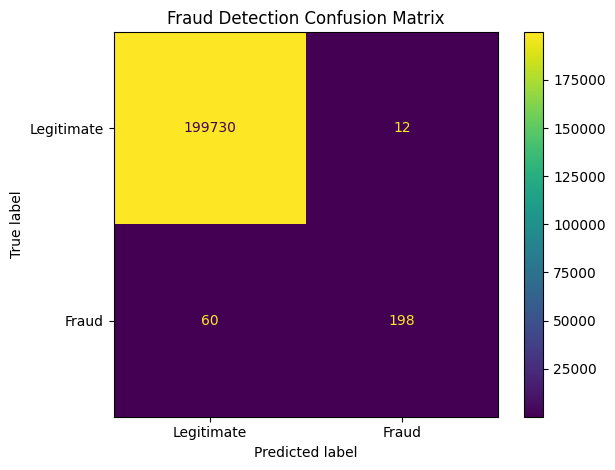

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot(values_format="d")
plt.title("Fraud Detection Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
%pip -q install shap

In [12]:
import shap

print("SHAP version:", shap.__version__)

background = X_train.sample(
    n=min(100, len(X_train)),
    random_state=42
)

X_explain = X_test.sample(
    n=min(200, len(X_test)),
    random_state=42
)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_explain)

# Different SHAP versions return different shapes.
if isinstance(shap_values, list):
    fraud_shap = shap_values[1]
elif getattr(shap_values, "ndim", 0) == 3:
    fraud_shap = shap_values[:, :, 1]
else:
    fraud_shap = shap_values

print("SHAP explanation generated!")

SHAP version: 0.54.1
SHAP explanation generated!


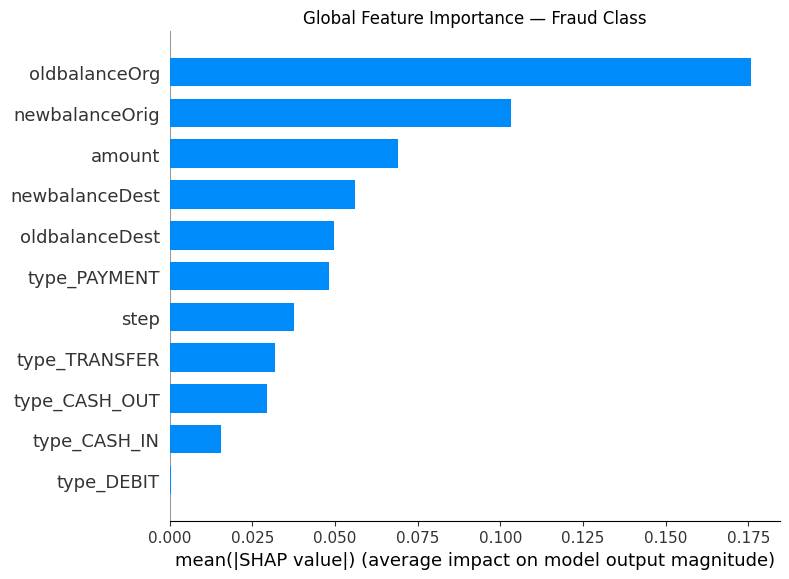

In [13]:
shap.summary_plot(
    fraud_shap,
    X_explain,
    plot_type="bar",
    show=False
)

plt.title("Global Feature Importance — Fraud Class")
plt.tight_layout()
plt.show()

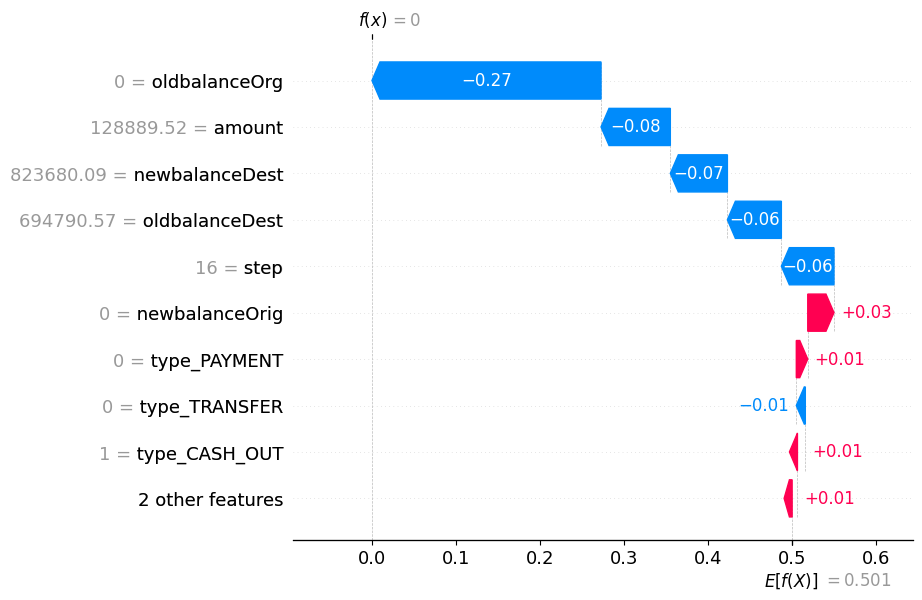

In [14]:
row_index = 0

shap.plots.waterfall(
    shap.Explanation(
        values=fraud_shap[row_index],
        base_values=(
            explainer.expected_value[1]
            if isinstance(explainer.expected_value, (list, np.ndarray))
            and np.asarray(explainer.expected_value).ndim > 0
            else explainer.expected_value
        ),
        data=X_explain.iloc[row_index].values,
        feature_names=X_explain.columns.tolist()
    ),
    max_display=10
)

In [15]:
sample_transaction = {
    "step": 100,
    "type": "TRANSFER",
    "amount": 50000.0,
    "oldbalanceOrg": 60000.0,
    "newbalanceOrig": 10000.0,
    "oldbalanceDest": 2000.0,
    "newbalanceDest": 52000.0
}

new_df = pd.DataFrame([sample_transaction])

new_encoded = pd.get_dummies(
    new_df,
    columns=["type"],
    dtype=int
)

new_encoded = new_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

prediction = model.predict(new_encoded)[0]
probability = model.predict_proba(new_encoded)[0, 1]

print("Prediction:", "FRAUD" if prediction == 1 else "LEGITIMATE")
print(f"Model fraud score: {probability:.2%}")

Prediction: LEGITIMATE
Model fraud score: 0.00%


In [16]:
import joblib

output_dir = "/content/drive/MyDrive/paysim_project_outputs"
os.makedirs(output_dir, exist_ok=True)

joblib.dump(model, os.path.join(output_dir, "fraud_detection_model.pkl"))
joblib.dump(X_train.columns.tolist(), os.path.join(output_dir, "feature_columns.pkl"))

print("Model and feature columns saved to Google Drive!")

Model and feature columns saved to Google Drive!


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

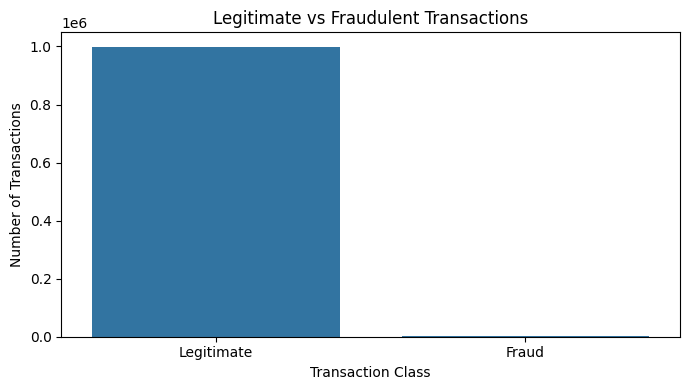

In [18]:
fraud_counts = df["isFraud"].value_counts().sort_index()

plt.figure(figsize=(7, 4))

sns.barplot(
    x=fraud_counts.index,
    y=fraud_counts.values
)

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.title("Legitimate vs Fraudulent Transactions")

plt.tight_layout()
plt.show()

In [19]:

# STEP 1: Load the saved fraud detection model

from google.colab import drive
drive.mount('/content/drive')

import os
import joblib
import pandas as pd
import numpy as np

# Folder where the model was saved
output_dir = "/content/drive/MyDrive/paysim_project_outputs"

model_path = os.path.join(
    output_dir, "fraud_detection_model.pkl"
)

features_path = os.path.join(
    output_dir, "feature_columns.pkl"
)

# Check whether saved files exist
assert os.path.exists(model_path), "Model file not found!"
assert os.path.exists(features_path), "Feature file not found!"

# Load model and feature names
model = joblib.load(model_path)
feature_columns = joblib.load(features_path)

print("Model loaded successfully!")
print("Number of features:", len(feature_columns))
print("Features:", feature_columns)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully!
Number of features: 11
Features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [20]:

# STEP 2: Create a transaction prediction function

def predict_transaction(
    step,
    transaction_type,
    amount,
    oldbalanceOrg,
    newbalanceOrig,
    oldbalanceDest,
    newbalanceDest
):
    # Prepare transaction data
    transaction = pd.DataFrame([{
        "step": step,
        "type": transaction_type,
        "amount": amount,
        "oldbalanceOrg": oldbalanceOrg,
        "newbalanceOrig": newbalanceOrig,
        "oldbalanceDest": oldbalanceDest,
        "newbalanceDest": newbalanceDest
    }])

    # Encode transaction type
    transaction = pd.get_dummies(
        transaction,
        columns=["type"],
        dtype=int
    )

    # Match the exact training feature order
    transaction = transaction.reindex(
        columns=feature_columns,
        fill_value=0
    )

    # Get prediction and probability score
    prediction = model.predict(transaction)[0]
    fraud_probability = model.predict_proba(
        transaction
    )[0, 1]

    result = {
        "Prediction": (
            "POTENTIAL FRAUD"
            if prediction == 1
            else "LIKELY LEGITIMATE"
        ),
        "Fraud score (%)": round(
            fraud_probability * 100, 2
        )
    }

    return result


# Test the function with a sample transaction
result = predict_transaction(
    step=100,
    transaction_type="TRANSFER",
    amount=50000,
    oldbalanceOrg=60000,
    newbalanceOrig=10000,
    oldbalanceDest=2000,
    newbalanceDest=52000
)

print(result)


{'Prediction': 'LIKELY LEGITIMATE', 'Fraud score (%)': np.float64(0.0)}


In [21]:

# STEP 3: Test multiple transaction scenarios

test_cases = [
    {
        "name": "Normal payment",
        "step": 100,
        "transaction_type": "PAYMENT",
        "amount": 500,
        "oldbalanceOrg": 5000,
        "newbalanceOrig": 4500,
        "oldbalanceDest": 1000,
        "newbalanceDest": 1500
    },
    {
        "name": "Large transfer",
        "step": 100,
        "transaction_type": "TRANSFER",
        "amount": 50000,
        "oldbalanceOrg": 60000,
        "newbalanceOrig": 10000,
        "oldbalanceDest": 2000,
        "newbalanceDest": 52000
    },
    {
        "name": "Small transfer",
        "step": 100,
        "transaction_type": "TRANSFER",
        "amount": 1000,
        "oldbalanceOrg": 2000,
        "newbalanceOrig": 1000,
        "oldbalanceDest": 500,
        "newbalanceDest": 1500
    }
]

results = []

for case in test_cases:
    result = predict_transaction(
        step=case["step"],
        transaction_type=case["transaction_type"],
        amount=case["amount"],
        oldbalanceOrg=case["oldbalanceOrg"],
        newbalanceOrig=case["newbalanceOrig"],
        oldbalanceDest=case["oldbalanceDest"],
        newbalanceDest=case["newbalanceDest"]
    )

    results.append({
        "Test Case": case["name"],
        "Prediction": result["Prediction"],
        "Fraud Score (%)": float(result["Fraud score (%)"])
    })

results_df = pd.DataFrame(results)
display(results_df)


,Test Case,Prediction,Fraud Score (%)
0,Normal payment,LIKELY LEGITIMATE,0.0
1,Large transfer,LIKELY LEGITIMATE,0.0
2,Small transfer,LIKELY LEGITIMATE,1.0


In [22]:

# STEP 4: Diagnose model predictions

print("Model classes:", model.classes_)
print("\nSaved feature columns:")
print(feature_columns)

print("\nModel feature importances:")
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

# Inspect the probabilities for one transaction
sample = pd.DataFrame([{
    "step": 100,
    "type": "TRANSFER",
    "amount": 50000,
    "oldbalanceOrg": 60000,
    "newbalanceOrig": 10000,
    "oldbalanceDest": 2000,
    "newbalanceDest": 52000
}])

sample = pd.get_dummies(
    sample, columns=["type"], dtype=int
)
sample = sample.reindex(
    columns=feature_columns, fill_value=0
)

print("\nInput passed to model:")
display(sample)

print("\nProbability for each class:")
print(model.predict_proba(sample)[0])

print("\nPredicted class:")
print(model.predict(sample)[0])


Model classes: [0 1]

Saved feature columns:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']

Model feature importances:


,Feature,Importance
2,oldbalanceOrg,0.320930
3,newbalanceOrig,0.165697
1,amount,0.153715
9,type_PAYMENT,0.068769
10,type_TRANSFER,0.063468
5,newbalanceDest,0.052919
0,step,0.051938
4,oldbalanceDest,0.046692
6,type_CASH_IN,0.041934
7,type_CASH_OUT,0.033752



Input passed to model:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,100,50000,60000,10000,2000,52000,0,0,0,0,1



Probability for each class:
[1. 0.]

Predicted class:
0


In [23]:

# STEP 5: Evaluate model on the original test dataset

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import pandas as pd

# Check that previous training variables are available
if "X_test" not in globals() or "y_test" not in globals():
    raise NameError(
        "X_test or y_test is missing. "
        "Run your earlier train-test split cells first."
    )

# Align test data with the saved model features
X_test_check = X_test.reindex(
    columns=feature_columns,
    fill_value=0
)

# Predict classes and probabilities
y_true = np.asarray(y_test)
y_pred = model.predict(X_test_check)
fraud_scores = model.predict_proba(X_test_check)[:, 1]

print("Actual class counts:")
print(pd.Series(y_true).value_counts().sort_index())

print("\nPredicted class counts:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nFraud probability summary:")
print("Minimum:", fraud_scores.min())
print("Maximum:", fraud_scores.max())
print("Mean:", fraud_scores.mean())

# Show actual fraud examples from the test set
fraud_indices = np.where(y_true == 1)[0]

if len(fraud_indices) > 0:
    sample_indices = fraud_indices[:5]

    fraud_examples = X_test_check.iloc[sample_indices].copy()
    fraud_examples["Actual label"] = 1
    fraud_examples["Predicted label"] = y_pred[sample_indices]
    fraud_examples["Fraud score (%)"] = (
        fraud_scores[sample_indices] * 100
    )

    print("\nFive actual fraud examples:")
    display(fraud_examples)


Actual class counts:
0    199742
1       258
Name: count, dtype: int64

Predicted class counts:
0    199790
1       210
Name: count, dtype: int64

Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    199742
       Fraud       0.94      0.77      0.85       258

    accuracy                           1.00    200000
   macro avg       0.97      0.88      0.92    200000
weighted avg       1.00      1.00      1.00    200000


Confusion matrix:
[[199730     12]
 [    60    198]]

Fraud probability summary:
Minimum: 0.0
Maximum: 0.9999998707097234
Mean: 0.003471942813021272

Five actual fraud examples:


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,Actual label,Predicted label,Fraud score (%)
999323,535,606501.57,606501.57,0.0,123759.67,730261.24,0,1,0,0,0,1,1,80.909675
999174,253,168622.30,168622.30,0.0,941451.87,1110074.16,0,1,0,0,0,1,0,10.808565
999199,60,581421.85,581421.85,0.0,0.00,0.00,0,0,0,0,1,1,1,99.934909
999932,639,305846.12,305846.12,0.0,0.00,305846.12,0,1,0,0,0,1,0,40.682311
998797,229,143332.00,143332.00,0.0,482652.15,716367.34,0,1,0,0,0,1,0,22.152008


In [24]:

%pip -q install gradio


In [ ]:

import gradio as gr

def fraud_detection_app(
    transaction_type,
    step,
    amount,
    oldbalanceOrg,
    newbalanceOrig,
    oldbalanceDest,
    newbalanceDest
):
    try:
        result = predict_transaction(
            step=int(step),
            transaction_type=transaction_type,
            amount=float(amount),
            oldbalanceOrg=float(oldbalanceOrg),
            newbalanceOrig=float(newbalanceOrig),
            oldbalanceDest=float(oldbalanceDest),
            newbalanceDest=float(newbalanceDest)
        )

        prediction = result["Prediction"]
        score = float(result["Fraud score (%)"])

        if prediction == "POTENTIAL FRAUD":
            message = (
                "⚠️ Potential Fraud Detected\n"
                "Please review this transaction carefully."
            )
        else:
            message = (
                "✅ Likely Legitimate Transaction\n"
                "The model did not flag this transaction as fraud."
            )

        return message, round(score, 2)

    except Exception as e:
        return f"Error: {str(e)}", 0.0


demo = gr.Interface(
    fn=fraud_detection_app,
    inputs=[
        gr.Dropdown(
            choices=[
                "CASH_IN",
                "CASH_OUT",
                "DEBIT",
                "PAYMENT",
                "TRANSFER"
            ],
            value="TRANSFER",
            label="Transaction Type"
        ),
        gr.Number(value=100, label="Step"),
        gr.Number(value=50000, label="Transaction Amount"),
        gr.Number(value=60000, label="Original Account Balance"),
        gr.Number(value=10000, label="New Original Balance"),
        gr.Number(value=2000, label="Destination Balance Before"),
        gr.Number(value=52000, label="Destination Balance After")
    ],
    outputs=[
        gr.Textbox(label="Detection Result"),
        gr.Number(label="Fraud Score (%)")
    ],
    title="Digital Payment Fraud Detection",
    description=(
        "Machine Learning-based transaction screening "
        "with a Random Forest model."
    ),
    flagging_mode="never"
)

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c620ddb799bd0aa11b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# STEP 7: Find a correctly detected fraud example

import numpy as np
import pandas as pd

X_check = X_test.reindex(
    columns=feature_columns,
    fill_value=0
)

y_actual = np.asarray(y_test)
y_predicted = model.predict(X_check)
fraud_scores = model.predict_proba(X_check)[:, 1]

# Find an actual fraud transaction predicted as fraud
matches = np.where(
    (y_actual == 1) & (y_predicted == 1)
)[0]

if len(matches) == 0:
    print("No correctly detected fraud example found.")
else:
    idx = matches[0]
    row = X_check.iloc[idx]

    # Recover transaction type from one-hot columns
    type_columns = [
        "type_CASH_IN",
        "type_CASH_OUT",
        "type_DEBIT",
        "type_PAYMENT",
        "type_TRANSFER"
    ]

    active_types = [
        col.replace("type_", "")
        for col in type_columns
        if col in row.index and row[col] == 1
    ]

    print("Actual label: FRAUD")
    print("Predicted label:", int(y_predicted[idx]))
    print("Fraud score (%):", round(float(fraud_scores[idx]) * 100, 2))
    print("Transaction type:", active_types)
    print("\nEnter these values in your Gradio app:")

    for col in [
        "step", "amount", "oldbalanceOrg",
        "newbalanceOrig", "oldbalanceDest",
        "newbalanceDest"
    ]:
        print(f"{col}: {row[col]}")

    print("transaction_type:", active_types[0] if active_types else "CHECK TYPE")


In [ ]:

# STEP 9: Install SHAP for Explainable AI

%pip -q install shap

import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)
print("Model type:", type(model).__name__)
print("Number of input features:", len(feature_columns))


In [ ]:

# STEP 10: Calculate SHAP explanations

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use a small sample to keep computation manageable
X_explain = X_test.reindex(
    columns=feature_columns,
    fill_value=0
).sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Create SHAP explainer for Random Forest
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_explain)

print("SHAP values calculated successfully!")
print("Sample rows:", len(X_explain))
print("Feature count:", len(feature_columns))
print("SHAP output type:", type(shap_values))
print("SHAP output shape:",
      np.asarray(shap_values, dtype=object).shape)


In [ ]:

# STEP 11: Global feature importance using SHAP

# Handle common SHAP output formats
if isinstance(shap_values, list):
    fraud_shap = np.asarray(shap_values[1])
else:
    values_array = np.asarray(shap_values)

    if values_array.ndim == 3:
        # Rows x features x classes
        fraud_shap = values_array[:, :, 1]
    else:
        fraud_shap = values_array

# Calculate average absolute SHAP value per feature
importance = np.abs(fraud_shap).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Mean absolute SHAP": importance
}).sort_values(
    "Mean absolute SHAP",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean absolute SHAP"]
)
plt.xlabel("Mean absolute SHAP value")
plt.title("SHAP Feature Importance — Fraud Detection")
plt.tight_layout()
plt.show()

display(shap_importance.sort_values(
    "Mean absolute SHAP",
    ascending=False
))


In [ ]:

# STEP 13: Explain one fraud prediction using SHAP

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare test data in the model's expected feature order
X_test_check = X_test.reindex(
    columns=feature_columns,
    fill_value=0
)

y_true = np.asarray(y_test)
y_pred = model.predict(X_test_check)

# Find a real fraud transaction correctly detected by the model
fraud_indices = np.where(
    (y_true == 1) & (y_pred == 1)
)[0]

if len(fraud_indices) == 0:
    print("No correctly detected fraud example found.")
else:
    # Explain the first correctly detected fraud
    idx = fraud_indices[0]
    X_one = X_test_check.iloc[[idx]]

    # Calculate SHAP explanation
    explainer = shap.TreeExplainer(model)
    explanation = explainer(X_one)

    # Extract SHAP values for fraud class (class 1)
    values = np.asarray(explanation.values)
    bases = np.asarray(explanation.base_values)

    if values.ndim == 3:
        fraud_values = values[0, :, 1]
    else:
        fraud_values = values[0]

    if bases.ndim == 2:
        fraud_base = bases[0, 1]
    else:
        fraud_base = bases.reshape(-1)[0]

    # Display the transaction and its model score
    fraud_score = model.predict_proba(X_one)[0, 1] * 100

    print("Actual label: FRAUD")
    print("Predicted label:", int(y_pred[idx]))
    print("Fraud score (%):", round(float(fraud_score), 2))

    # Plot explanation
    waterfall_explanation = shap.Explanation(
        values=fraud_values,
        base_values=fraud_base,
        data=X_one.iloc[0].values,
        feature_names=feature_columns
    )

    shap.plots.waterfall(
        waterfall_explanation,
        max_display=11,
        show=False
    )
    plt.title("SHAP Explanation for One Fraud Prediction")
    plt.tight_layout()
    plt.show()


In [ ]:

# STEP 14: Gradio app with SHAP explanations

import gradio as gr
import shap
import numpy as np
import pandas as pd

# Create the SHAP explainer
shap_explainer = shap.TreeExplainer(model)


def explainable_fraud_detection(
    transaction_type,
    step,
    amount,
    oldbalanceOrg,
    newbalanceOrig,
    oldbalanceDest,
    newbalanceDest
):
    try:
        # Validate and prepare user input
        transaction = pd.DataFrame([{
            "step": step,
            "type": transaction_type,
            "amount": amount,
            "oldbalanceOrg": oldbalanceOrg,
            "newbalanceOrig": newbalanceOrig,
            "oldbalanceDest": oldbalanceDest,
            "newbalanceDest": newbalanceDest
        }])

        # Encode transaction type
        transaction = pd.get_dummies(
            transaction,
            columns=["type"],
            dtype=int
        )

        # Match the exact model training columns
        transaction = transaction.reindex(
            columns=feature_columns,
            fill_value=0
        )

        # Predict fraud class and probability
        prediction = int(model.predict(transaction)[0])
        class_index = list(model.classes_).index(1)

        fraud_probability = float(
            model.predict_proba(transaction)[0, class_index]
        )

        score = round(fraud_probability * 100, 2)

        if prediction == 1:
            result = (
                "POTENTIAL FRAUD DETECTED\n"
                "Review this transaction carefully."
            )
        else:
            result = (
                "LIKELY LEGITIMATE\n"
                "The model did not flag this transaction."
            )

        # Calculate SHAP values for this transaction
        explanation = shap_explainer(transaction)
        values = np.asarray(explanation.values)

        # Extract the SHAP values for class 1 (fraud)
        if values.ndim == 3:
            fraud_values = values[0, :, class_index]
        else:
            fraud_values = values[0]

        # Rank the strongest positive and negative contributions
        factors = pd.DataFrame({
            "Feature": feature_columns,
            "Transaction Value": transaction.iloc[0].values,
            "SHAP Contribution": fraud_values
        })

        factors["Direction"] = np.where(
            factors["SHAP Contribution"] > 0,
            "Increases fraud-class output",
            np.where(
                factors["SHAP Contribution"] < 0,
                "Decreases fraud-class output",
                "No contribution"
            )
        )

        factors["Abs Contribution"] = factors[
            "SHAP Contribution"
        ].abs()

        factors = factors.sort_values(
            "Abs Contribution",
            ascending=False
        ).head(8)

        # Create readable explanation text
        lines = [
            f"Model fraud score: {score}%",
            "",
            "Top SHAP contributions:",
            "(Positive = pushes fraud-class output up;",
            " negative = pushes it down.)",
            ""
        ]

        for _, row in factors.iterrows():
            lines.append(
                f'{row["Feature"]} = {row["Transaction Value"]}: '
                f'{row["SHAP Contribution"]:+.4f} '
                f'({row["Direction"]})'
            )

        lines.extend([
            "",
            "Important: SHAP explains the model's prediction; "
            "it does not prove that a transaction is fraudulent."
        ])

        return result, score, "\n".join(lines)

    except Exception as e:
        return (
            f"Could not process transaction: {e}",
            0.0,
            "Please check the input values and model."
        )


# Build the updated web interface
demo = gr.Interface(
    fn=explainable_fraud_detection,
    inputs=[
        gr.Dropdown(
            choices=[
                "CASH_IN",
                "CASH_OUT",
                "DEBIT",
                "PAYMENT",
                "TRANSFER"
            ],
            value="CASH_OUT",
            label="Transaction Type"
        ),
        gr.Number(value=535, label="Step"),
        gr.Number(value=606501.57, label="Transaction Amount"),
        gr.Number(value=606501.57, label="Original Account Balance"),
        gr.Number(value=0, label="New Original Balance"),
        gr.Number(value=123759.67, label="Destination Balance Before"),
        gr.Number(value=730261.24, label="Destination Balance After")
    ],
    outputs=[
        gr.Textbox(label="Detection Result"),
        gr.Number(label="Fraud Score (%)"),
        gr.Textbox(
            label="Explainable AI — SHAP Reasons",
            lines=14
        )
    ],
    title="Digital Payment Fraud Detection",
    description=(
        "Random Forest prediction with SHAP-based "
        "explanations for individual transactions."
    ),
    flagging_mode="never"
)

demo.launch(share=True, debug=True)


In [ ]:

# STEP 15: Train a Logistic Regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)
import pandas as pd

# Use the same train/test split as the Random Forest
X_train_lr = X_train.reindex(
    columns=feature_columns,
    fill_value=0
)

X_test_lr = X_test.reindex(
    columns=feature_columns,
    fill_value=0
)

# Logistic Regression with feature scaling
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Train the baseline model
lr_model.fit(X_train_lr, y_train)

print("Logistic Regression trained successfully!")

# Predict test results
lr_predictions = lr_model.predict(X_test_lr)
lr_probabilities = lr_model.predict_proba(X_test_lr)[:, 1]

print("\nLogistic Regression Results")
print("Precision:",
      round(precision_score(y_test, lr_predictions, zero_division=0), 4))
print("Recall:",
      round(recall_score(y_test, lr_predictions, zero_division=0), 4))
print("F1-score:",
      round(f1_score(y_test, lr_predictions, zero_division=0), 4))
print("PR-AUC:",
      round(average_precision_score(y_test, lr_probabilities), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test, lr_probabilities), 4))


In [ ]:

# STEP 16: Compare Random Forest vs Logistic Regression

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Existing Random Forest predictions
rf_predictions = model.predict(X_test_lr)
rf_probabilities = model.predict_proba(X_test_lr)[:, 1]

# Logistic Regression predictions are from Step 15
lr_predictions = lr_model.predict(X_test_lr)
lr_probabilities = lr_model.predict_proba(X_test_lr)[:, 1]

def calculate_metrics(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        )
    }

comparison = pd.DataFrame([
    calculate_metrics(
        "Random Forest", y_test,
        rf_predictions, rf_probabilities
    ),
    calculate_metrics(
        "Logistic Regression", y_test,
        lr_predictions, lr_probabilities
    )
])

display(comparison.round(4))


In [ ]:

# STEP 18: Visual comparison of both models

import matplotlib.pyplot as plt
import numpy as np

metrics = ["Precision", "Recall", "F1-score", "PR-AUC", "ROC-AUC"]

rf_scores = [0.9429, 0.7674, 0.8462, 0.8650, 0.9945]
lr_scores = [0.0234, 0.9419, 0.0457, 0.5973, 0.9896]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, rf_scores, width, label="Random Forest")
plt.bar(x + width/2, lr_scores, width, label="Logistic Regression")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Model Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


In [ ]:

# STEP 20: Tune Logistic Regression decision threshold
# Use the validation set if available.
# Do NOT tune on the final test set for final reporting.

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Use validation data if you created it earlier.
# Otherwise, use this only for exploration, not final test reporting.
lr_scores = lr_model.predict_proba(X_test_lr)[:, 1]
y_true = np.asarray(y_test)

thresholds = np.arange(0.10, 0.91, 0.05)
rows = []

for threshold in thresholds:
    predictions = (lr_scores >= threshold).astype(int)

    rows.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(4))


In [ ]:

# STEP 21: Select Logistic Regression threshold using validation data

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import numpy as np
import pandas as pd

# Split training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train.reindex(columns=feature_columns, fill_value=0),
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a separate model for threshold selection
lr_tuning_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

lr_tuning_model.fit(X_subtrain, y_subtrain)

# Get validation probabilities
val_scores = lr_tuning_model.predict_proba(X_val)[:, 1]

# Compare thresholds on validation data only
rows = []

for threshold in np.arange(0.10, 0.96, 0.05):
    val_predictions = (val_scores >= threshold).astype(int)

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

validation_results = pd.DataFrame(rows)

display(validation_results.round(4))

# Select the threshold with the best validation F1-score
best_row = validation_results.loc[
    validation_results["F1-score"].idxmax()
]

print("\nSelected validation threshold:",
      best_row["Threshold"])
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1-score"], 4))


In [ ]:

# STEP 22: Final evaluation on the untouched test set

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
import pandas as pd
import numpy as np

# Use the selected threshold from validation
selected_threshold = float(best_row["Threshold"])

# Evaluate the validation-trained Logistic Regression model
# on the original untouched test set
X_final_test = X_test.reindex(
    columns=feature_columns,
    fill_value=0
)

y_final = np.asarray(y_test)

lr_test_scores = lr_tuning_model.predict_proba(
    X_final_test
)[:, 1]

lr_test_predictions = (
    lr_test_scores >= selected_threshold
).astype(int)

print("Selected threshold:", selected_threshold)

print("\nClassification Report:")
print(classification_report(
    y_final,
    lr_test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_final,
    lr_test_predictions,
    labels=[0, 1]
))

print("PR-AUC:",
      round(average_precision_score(y_final, lr_test_scores), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_final, lr_test_scores), 4))


In [ ]:

# STEP 23: Save final model comparison

import os
import pandas as pd
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Random Forest: original threshold (model.predict)
rf_pred = model.predict(X_final_test)
rf_prob = model.predict_proba(X_final_test)[:, 1]

# Logistic Regression: validation-selected threshold
lr_pred = (lr_test_scores >= selected_threshold).astype(int)
lr_prob = lr_test_scores

def get_metrics(name, y_true, pred, prob):
    return {
        "Model": name,
        "Threshold": "Default" if name == "Random Forest" else selected_threshold,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1-score": f1_score(y_true, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, prob),
        "ROC-AUC": roc_auc_score(y_true, prob)
    }

final_comparison = pd.DataFrame([
    get_metrics("Random Forest", y_final, rf_pred, rf_prob),
    get_metrics("Logistic Regression", y_final, lr_pred, lr_prob)
])

display(final_comparison.round(4))

# Save results to Google Drive
output_dir = "/content/drive/MyDrive/paysim_project_outputs"
os.makedirs(output_dir, exist_ok=True)

comparison_path = os.path.join(
    output_dir, "final_model_comparison.csv"
)

final_comparison.to_csv(comparison_path, index=False)

print("\nFinal comparison saved to:")
print(comparison_path)


In [ ]:

# STEP 24: Plot final model comparison

import matplotlib.pyplot as plt

metrics = ["Precision", "Recall", "F1-score", "PR-AUC", "ROC-AUC"]
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

for i, row in final_comparison.iterrows():
    scores = [row[m] for m in metrics]
    offset = (i - 0.5) * width
    plt.bar(x + offset, scores, width, label=row["Model"])

plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Final Test Set: Model Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

graph_path = os.path.join(
    output_dir, "final_model_comparison.png"
)
plt.savefig(graph_path, dpi=200, bbox_inches="tight")
plt.show()

print("Graph saved to:", graph_path)
